# Table 4.1 as Code

Nilsson & Riedel's Table 4.1 defines eight words: **node, essential node, path,
branch, essential branch, loop, mesh, planar circuit**. They look like vocabulary,
but they're really an **algorithm**. Together they tell you how many equations a
circuit needs and which ones to write.

This notebook turns every definition into a function that runs on a netlist, then
writes and solves the circuit equations in SymPy **three independent ways**:

| method | unknowns | equations | works when |
|---|---|---|---|
| branch-current | $b_e$ essential-branch currents | $n_e - 1$ KCL + $b_e - n_e + 1$ KVL (loop basis) | always |
| node-voltage | $n_e - 1$ node voltages | $n_e - 1$ KCL | always |
| mesh-current | $b_e - n_e + 1$ mesh currents | one KVL per mesh | **planar** circuits only |

If all three give the same currents, and Tellegen's theorem $\sum v_k i_k = 0$
holds, the equations are right.

Module: [`dgs/circuit_terminology.py`](../dgs/circuit_terminology.py). The example
circuit is in the *style* of Fig. 4.3 but is not the textbook's circuit.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
from IPython.display import display, Math

from dgs.circuit_terminology import (
    nodes, essential_nodes, essential_branches, branch_label, loop_basis, meshes,
    is_planar, table_4_1, branch_current_solution, node_voltage_solution,
    mesh_current_solution, tellegen_sum,
)

def draw_circuit(elements, pos, ax, title=""):
    count, seen = {}, {}
    for e in elements:
        key = frozenset((e[1], e[2])); count[key] = count.get(key, 0) + 1
    ess = set(essential_nodes(elements))
    for e in elements:
        key = frozenset((e[1], e[2])); seen[key] = seen.get(key, 0) + 1
        m, i = count[key], seen[key]
        rad = 0.0 if m == 1 else (i - (m + 1)/2) * 0.5
        if (str(e[1]), str(e[2])) > (str(e[2]), str(e[1])):
            rad = -rad                      # same bend side regardless of a/b order
        col = {"R": "k", "V": "C3", "I": "C0"}[e[3]]
        p1, p2 = np.array(pos[e[1]]), np.array(pos[e[2]])
        ax.add_patch(FancyArrowPatch(p1, p2, connectionstyle=f"arc3,rad={rad}", arrowstyle="-",
                                     color=col, lw=2, shrinkA=8, shrinkB=8))
        mid = (p1 + p2)/2; d = p2 - p1; nrm = np.array([-d[1], d[0]]) / (np.hypot(*d) + 1e-12)
        lab = mid - nrm*rad*np.hypot(*d)*0.5 if rad else p1 + 0.3*d   # off-centre: crossings stay readable
        ax.text(*lab, e[0], color=col, fontsize=10, ha="center", va="center",
                bbox=dict(fc="white", ec="none", pad=0.5))
    for n, (x, y) in pos.items():
        ax.plot(x, y, "o", ms=13 if n in ess else 7, color="C1" if n in ess else "0.4")
        ax.text(x, y + 0.13, n, ha="center", fontsize=11, weight="bold")
    ax.set_aspect("equal"); ax.axis("off"); ax.margins(0.12); ax.set_title(title, pad=18)

# 1. The netlist and the eight definitions

A netlist is just a list of `(name, node_a, node_b, kind, value)`:

- `'R'` is a resistor.
- `'V'` is a voltage source with **+ at node a**.
- `'I'` is a current source driving current **through itself from a to b**.

The definitions become code:

| term | definition | code |
|---|---|---|
| node | where ≥ 2 elements join | every vertex of the graph (degree ≥ 2) |
| essential node | where ≥ 3 elements join | degree ≥ 3 |
| branch | path joining two nodes | each single element |
| essential branch | joins two essential nodes, passing only non-essential ones | walk from an essential node until you reach another |
| loop | path that returns to its start | a cycle |
| mesh | loop enclosing no other loop | an interior face of a planar drawing |
| planar circuit | can be drawn with no crossings | `networkx.check_planarity` |

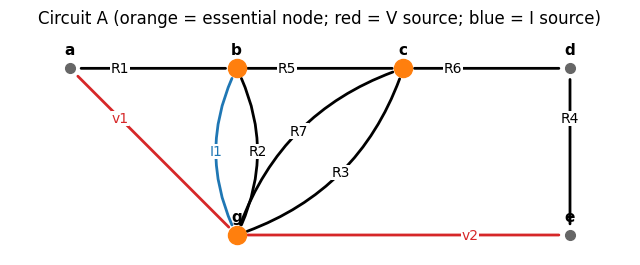

n (nodes)                        6
n_e (essential nodes)            3
b (branches = elements)          10
b_e (essential branches)         7
KCL equations n_e - 1            2
KVL equations b_e - (n_e - 1)    5
planar                           True
meshes                           5
example node (non-essential)     a
example essential node           b
example branch                   v1
example essential branch         I1
example loop                     R6 - R4 - v2 ; reverse R7
example mesh                     R1 - v1 ; reverse I1


In [2]:
R = sp.Integer
A = [("v1", "a", "g", "V", R(40)), ("R1", "a", "b", "R", R(5)),  ("R2", "b", "g", "R", R(10)),
     ("R5", "b", "c", "R", R(4)),  ("R3", "c", "g", "R", R(20)), ("R7", "c", "g", "R", R(20)),
     ("R6", "c", "d", "R", R(6)),  ("R4", "d", "e", "R", R(2)),  ("v2", "e", "g", "V", R(10)),
     ("I1", "g", "b", "I", R(2))]
posA = {"a": (0, 1.6), "b": (1.6, 1.6), "c": (3.2, 1.6), "d": (4.8, 1.6), "e": (4.8, 0), "g": (1.6, 0)}

fig, ax = plt.subplots(figsize=(8, 4))
draw_circuit(A, posA, ax, "Circuit A (orange = essential node; red = V source; blue = I source)")
plt.show()
for k, v in table_4_1(A).items():
    print(f"{k:32s} {v}")

In [3]:
print("essential branches (start → end):")
for k, br in enumerate(essential_branches(A)):
    print(f"  [{k}] {br.start} → {br.end}:  {branch_label(br)}")
fmt = lambda loop: "  +  ".join(("" if s > 0 else "−") + f"[{k}]" for k, s in loop)
print("\nloop basis (from a spanning tree):"); [print("  ", fmt(l)) for l in loop_basis(A)]
print("\nmeshes (interior faces):");        [print("  ", fmt(m)) for m in meshes(A)]

essential branches (start → end):
  [0] b → g:  I1
  [1] b → g:  R1 - v1
  [2] b → g:  R2
  [3] b → c:  R5
  [4] c → g:  R3
  [5] c → g:  R6 - R4 - v2
  [6] c → g:  R7

loop basis (from a spanning tree):
   [5]  +  −[6]
   [4]  +  −[6]
   −[0]  +  [2]
   −[1]  +  [2]
   −[3]  +  [2]  +  −[6]

meshes (interior faces):
   [1]  +  −[0]
   [2]  +  −[1]
   −[4]  +  [6]
   −[6]  +  [5]
   [3]  +  [4]  +  −[2]


[None, None, None, None, None]

**Counting.** There are $n_e = 3$ essential nodes and $b_e = 7$ essential
branches, so we need $n_e - 1 = 2$ KCL equations and $b_e - (n_e - 1) = 5$ KVL
equations: 7 equations for 7 unknowns. For a planar circuit, the number of meshes
equals $b - n + 1 = 10 - 6 + 1 = 5$. That's **Euler's formula** for planar graphs
(V − E + F = 2), and it's why the two counts agree.

A loop basis and a set of meshes both contain 5 loops, but they're *different*
loops. Any 5 independent loops give valid KVL equations. Meshes are just one
especially tidy choice, available only for planar circuits.

# 2. Writing the equations: branch-current method

Each essential branch has one current $i_k$, defined from its start to its end.
Its voltage is $V_\text{start} - V_\text{end} = R_k i_k + (\text{source EMFs})$.
A branch containing a current source has a known current but an unknown voltage
$u_k$, so the number of unknowns doesn't change.

In [4]:
eqs, i_bc, v_bc = branch_current_solution(A, "g")
for e in eqs:
    display(e)
print("solution (essential-branch currents, A):")
for k, c in i_bc.items():
    print(f"  [{k}] {branch_label(essential_branches(A)[k]):14s} i = {c}  = {float(c):+.4f}")
print("Tellegen  Σ v_k i_k =", tellegen_sum(A, i_bc, v_bc))

Eq(i_1 + i_2 + i_3 - 2, 0)

Eq(-i_3 + i_4 + i_5 + i_6, 0)

Eq(8*i_5 - 20*i_6 + 10, 0)

Eq(20*i_4 - 20*i_6, 0)

Eq(10*i_2 - u_0, 0)

Eq(-5*i_1 + 10*i_2 - 40, 0)

Eq(10*i_2 - 4*i_3 - 20*i_6, 0)

solution (essential-branch currents, A):
  [0] I1             i = -2  = -2.0000
  [1] R1 - v1        i = -154/53  = -2.9057
  [2] R2             i = 135/53  = +2.5472
  [3] R5             i = 125/53  = +2.3585
  [4] R3             i = 85/106  = +0.8019
  [5] R6 - R4 - v2   i = 40/53  = +0.7547
  [6] R7             i = 85/106  = +0.8019
Tellegen  Σ v_k i_k = 0


# 3. Node-voltage method: only $n_e - 1 = 2$ equations

Ground one essential node. Every branch current is then
$i_k = (V_\text{start} - V_\text{end} - \text{EMF})/R_k$, and KCL at the other
essential nodes is all you need. **Choosing essential nodes instead of all nodes
is what saves work.** Node $a$ (between $v_1$ and $R_1$) never needs its own
equation.

In [5]:
eqs, i_nv, V = node_voltage_solution(A, "g")
for e in eqs:
    display(e)
print("node voltages:", V)
print("same currents as branch-current method:", i_nv == i_bc)

Eq(11*V_b/20 - V_c/4 - 10, 0)

Eq(-V_b/4 + 19*V_c/40 - 5/4, 0)

node voltages: {'b': 1350/53, 'c': 850/53, 'g': 0}
same currents as branch-current method: True


# 4. Mesh-current method, and why it needs a planar circuit

Give each mesh a circulating current $j_m$. A branch shared by two meshes carries
$j_m - j_{m'}$, because the two faces traverse it in opposite directions. KCL is
then **automatically** satisfied, and only one KVL per mesh remains.

A current source complicates this (it needs a "supermesh"), so here the mesh method
is shown on circuit A with $I_1$ removed. All three methods are compared on that
circuit.

In [6]:
A2 = [e for e in A if e[0] != "I1"]
eqs, i_mc = mesh_current_solution(A2)
for e in eqs:
    display(e)
_, i_b2, _ = branch_current_solution(A2, "g")
_, i_n2, _ = node_voltage_solution(A2, "g")
print(f"{'branch':16s} {'branch-current':>15s} {'node-voltage':>13s} {'mesh-current':>13s}")
for k, br in enumerate(essential_branches(A2)):
    print(f"{branch_label(br):16s} {str(i_b2[k]):>15s} {str(i_n2[k]):>13s} {str(i_mc[k]):>13s}")
print("\nall three identical:", i_b2 == i_n2 == i_mc)

Eq(15*j_0 - 10*j_3 - 40, 0)

Eq(40*j_1 - 20*j_2 - 20*j_3, 0)

Eq(-20*j_1 + 28*j_2 + 10, 0)

Eq(-10*j_0 - 20*j_1 + 34*j_3, 0)

branch            branch-current  node-voltage  mesh-current
R1 - v1                 -614/159      -614/159      -614/159
R2                       329/159       329/159       329/159
R5                         95/53         95/53         95/53
R3                       215/318       215/318       215/318
R6 - R4 - v2              70/159        70/159        70/159
R7                       215/318       215/318       215/318

all three identical: True


# 5. Fully symbolic: the same three methods give the same formula

Here's the classic two-source, two-mesh circuit with symbolic values. The center
node voltage should reduce to **Millman's theorem**:
$V_n = \dfrac{v_1/R_1 + v_2/R_3}{1/R_1 + 1/R_2 + 1/R_3}$.

In [7]:
v1, v2, R1, R2, R3 = sp.symbols("v1 v2 R1 R2 R3", positive=True)
S = [("v1", "p", "0", "V", v1), ("R1", "p", "n", "R", R1), ("R2", "n", "0", "R", R2),
     ("R3", "n", "q", "R", R3), ("v2", "q", "0", "V", v2)]
_, iS_b, _ = branch_current_solution(S, "0")
_, iS_n, VS = node_voltage_solution(S, "0")
_, iS_m = mesh_current_solution(S)
display(Math(r"V_n = " + sp.latex(sp.factor(VS["n"]))))
millman = (v1/R1 + v2/R3)/(1/R1 + 1/R2 + 1/R3)
print("equals Millman:", sp.simplify(VS["n"] - millman) == 0)
for k, br in enumerate(essential_branches(S)):
    same = sp.simplify(iS_b[k] - iS_n[k]) == 0 and sp.simplify(iS_b[k] - iS_m[k]) == 0
    display(Math(rf"i_{{{branch_label(br)}}} = " + sp.latex(sp.factor(iS_b[k])) + rf"\quad(\text{{3 methods agree: {same}}})"))

<IPython.core.display.Math object>

equals Millman: True


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

# 6. A nonplanar circuit: meshes don't exist, loops still work

Wire 3 nodes to 3 other nodes, every pair connected. This is the graph
$K_{3,3}$, the "three utilities" puzzle, and it **cannot be drawn without a
crossing** (Kuratowski's theorem). It has no meshes, so the mesh method has
nothing to work with, but a spanning-tree loop basis still gives the right number
of independent KVL equations.

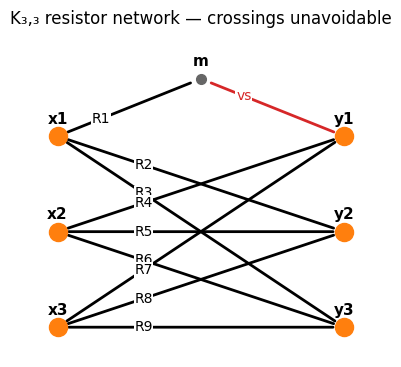

n_e (essential nodes)            6
b_e (essential branches)         9
KCL equations n_e - 1            5
KVL equations b_e - (n_e - 1)    4
planar                           False
meshes                           None

mesh method: nonplanar circuit: meshes do not exist -- use a loop basis
loop-basis branch currents == node-voltage currents: True    Tellegen: 0


In [8]:
K, c = [], 0
for a in ("x1", "x2", "x3"):
    for b in ("y1", "y2", "y3"):
        c += 1; K.append((f"R{c}", a, b, "R", R(c)))
K[0] = ("R1", "x1", "m", "R", R(1)); K.append(("vs", "m", "y1", "V", R(12)))
posK = {"x1": (0, 2), "x2": (0, 1), "x3": (0, 0), "y1": (3, 2), "y2": (3, 1), "y3": (3, 0), "m": (1.5, 2.6)}
fig, ax = plt.subplots(figsize=(6, 4)); draw_circuit(K, posK, ax, "K₃,₃ resistor network — crossings unavoidable"); plt.show()
t = table_4_1(K)
for k in ("n_e (essential nodes)", "b_e (essential branches)", "KCL equations n_e - 1",
          "KVL equations b_e - (n_e - 1)", "planar", "meshes"):
    print(f"{k:32s} {t[k]}")
try:
    mesh_current_solution(K)
except ValueError as err:
    print("\nmesh method:", err)
_, iK_b, vK_b = branch_current_solution(K)
_, iK_n, _ = node_voltage_solution(K)
print("loop-basis branch currents == node-voltage currents:", iK_b == iK_n,
      "   Tellegen:", tellegen_sum(K, iK_b, vK_b))

# 7. Which method should you pick?

Pick whichever needs **fewer equations**: $n_e - 1$ for node-voltage versus
$b_e - n_e + 1$ for mesh-current.

In [9]:
print(f"{'circuit':14s} {'node-voltage n_e-1':>19s} {'mesh/loop b_e-n_e+1':>21s}   pick")
for name, C in (("A", A), ("A without I1", A2), ("two-mesh", S), ("K3,3", K)):
    t = table_4_1(C)
    nv, ml = t["KCL equations n_e - 1"], t["KVL equations b_e - (n_e - 1)"]
    print(f"{name:14s} {nv:19d} {ml:21d}   {'node-voltage' if nv < ml else ('mesh' if t['planar'] else 'loop basis') if ml < nv else 'either'}")

circuit         node-voltage n_e-1   mesh/loop b_e-n_e+1   pick
A                                2                     5   node-voltage
A without I1                     2                     4   node-voltage
two-mesh                         1                     2   node-voltage
K3,3                             5                     4   loop basis


## Tools note: Python vs. C vs. MATLAB

| | strength for this job |
|---|---|
| **Python + SymPy** | exact symbolic equations (as here), with free tools like networkx, NumPy, and matplotlib |
| **MATLAB** | the Symbolic Math Toolbox and Simulink are standard in many EE courses; often licensed through your school |
| **C** | how SPICE engines are actually written: sparse numeric matrices, fast and low-level |

The *method* (essential nodes, then KCL, then KVL on a loop basis) is the same in
all three, and that's the transferable skill.

## Exercises
1. Add a dependent source (e.g. a VCVS, $v = \mu\,v_x$) as a new element kind. Which equation writer changes, and how?
2. Re-draw circuit A so a different face is the outer one. Do the mesh currents change? Do the branch currents?
3. Implement the **supermesh** so `mesh_current_solution` can handle $I_1$.
4. Prove that a branch shared by two meshes always appears with opposite signs. (Hint: each half-edge of a planar embedding belongs to exactly one face.)
5. Build $K_5$ (5 nodes, all pairs connected) from resistors and confirm it is nonplanar too.